# OCR confidence and bounding boxes

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/ocr_confidence_bounding_boxes/ocr_confidence_bounding_boxes.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/ocr_confidence_bounding_boxes/ocr_confidence_bounding_boxes.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/ocr_confidence_bounding_boxes).

Values that OCR extracts from invoice photos are mostly right, but checking every one by
hand takes as long as typing them in. Jev can check them instead: it boxes each value on
the photo and flags the ones that look wrong, so a reviewer only looks at those.

![Each extracted field gets a box on the invoice photo, the box tightens on a zoomed-in
pass, and a crop of it is checked against the value: the misread invoice numbers and date
turn orange for review, and every correct value turns blue](https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/ocr_confidence_bounding_boxes/ocr-confidence-hero.gif)

On these two supplier invoices, an extractor read the supplier, invoice number, date,
amount due and bank details, and got three values wrong. Jev flags all three.

Jev checks each value twice: against the whole page (the page check) and against a crop of
its box (the crop check). A value that scores below 0.25 on either check goes to review. In
the table, "extracted" is what the extractor read and "printed" is what the invoice says.

| invoice | field | extracted | printed | page check | crop check |
|---|---|---|---|---|---|
| Milkwood | invoice number | `AN400074` | `IN400074` | 0.88 | 0.18 |
| Siyakhula | invoice number | `INV03070` | `INV03079` | 0.02 | 0.04 |
| Siyakhula | date | `16/09/2028` | `16/09/2026` | 0.17 | 0.66 |

The code below starts from `extractions.json`, the values the OCR and LLM steps produced,
and leaves those two steps out. You can make that file with Tesseract and your LLM of
choice.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/ocr_confidence_bounding_boxes/ocr_confidence_bounding_boxes-diagram-0dcefd2aa0.png" alt="Diagram" width="1176">

## Setup

```bash
pip install ipython pillow 'typesafe-sdk[pil]>=0.7.5' 'cooksafe>=0.3.0,<0.4.0'
```

Then set `TYPESAFE_API_KEY`.

> **Note** - Images and `Box` questions are dreamer-ready, which means they are not yet
> ready for production, and their request format and answers can change between releases.
> They need Jev 1.14, and every request needs the `TypeSafe-Danger-Zone-Images: true`
> header. The client below sets that header.

The numbers below came from `jev-1.14.0` on 2026-10-15.

In [ ]:
%pip install -q 'typesafe-sdk[pil]>=0.7.5' 'pillow' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import io
import json
import os
import urllib.request
from pathlib import Path

from cooksafe import JsonCache
from IPython.display import display
from PIL import Image as PILImage
from PIL import ImageDraw, ImageFont
from typesafe_sdk import Box, Image, Noul, SystemOneResponse, TypeSafeClient

# Box questions need Jev 1.14 or later.
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
BAR = 0.25  # a check scoring below this flags the field
ZOOM = 3  # the zoomed region is three times the first box, and at least ZOOM_MIN of the page
ZOOM_MIN = (0.30, 0.15)  # width, height as fractions of the page
GROW = (0.25, 0.20)  # review margin around each box, as fractions of its width and height
MIN_SIDE, MAX_SIDE = 280, 1568  # the pixel range Jev accepts for each side of an image

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    headers={"TypeSafe-Danger-Zone-Images": "true"},
    timeout=120.0,
)


EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/ocr_confidence_bounding_boxes"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("ocr_confidence_bounding_boxes_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Load the photos and what the extractor read

The two photos are invoices a restaurant received from its suppliers, taken with a phone.
One is a creased carbon copy from Milkwood Mushrooms. The other is from Siyakhula Trading
and has a shadow down the middle, making it a challenging OCR task.

The extracted values are in `extractions.json`. We used Apple Vision's text recognition
(OCR) to read the photos, and an LLM to read the output of that and return the structured
values. Any extractor works here, because the check only needs the photo and the values.

In [ ]:
INPUTS = Path("inputs")  # the photos, keyed in extractions.json by file name
EXTRACTIONS = json.loads(download("extractions.json").read_text())
for photo in EXTRACTIONS:
    download(f"inputs/{photo}")
FIELDS = {
    # field: what it is, in the words every question uses
    "supplier_name": "the supplier's (seller's) business name",
    "invoice_number": "the invoice or document number",
    "invoice_date": "the invoice date",
    "amount_due": "the final total amount payable",
    "bank_name": "the name of the supplier's bank in the payment details",
    "account_holder": "the account holder name in the supplier's bank details",
    "account_number": "the supplier's bank account number",
    "branch_code": "the supplier's bank branch code",
}
SAME_VALUE = "Ignore differences in spacing, punctuation, currency symbols and letter case."

for photo, values in sorted(EXTRACTIONS.items()):
    with PILImage.open(INPUTS / photo) as page:
        print(f"{photo}  ({page.width} x {page.height} px)")
    for field, value in values.items():
        print(f"  {field:<16}{value}")

milkwood.jpg  (1393 x 1080 px)
  supplier_name   MILKWOOD mushrooms
  invoice_number  AN400074
  invoice_date    01/09/2026
  amount_due      504.70
  bank_name       Standard Bank
  account_holder  MILKWOOD
  account_number  080 11 4941
siyakhula.jpg  (899 x 1599 px)
  supplier_name   Siyakhula Trading Services (Pty) Ltd ta Siyakhula Trading
  invoice_number  INV03070
  invoice_date    16/09/2028
  amount_due      R1,305.65
  bank_name       Standard Bank
  account_holder  Siyakhula Trading
  account_number  10 13 205 260 5
  branch_code     051001


Jev accepts images between 280 and 1568 pixels on each side. Larger images are shrunk, and
small crops are enlarged so their text is readable. An image that is still too small goes
in the middle of a white canvas, and its place on the canvas is kept, so a box Jev draws on
the canvas can be converted back to a position on the crop.

In [ ]:
def as_image(picture: PILImage.Image, upscale_to: int | None = None) -> tuple[Image, tuple]:
    picture = picture.convert("RGB")
    if upscale_to and max(picture.size) < upscale_to:
        scale = upscale_to / max(picture.size)
        picture = picture.resize(
            (round(picture.width * scale), round(picture.height * scale)), PILImage.LANCZOS
        )
    picture.thumbnail((MAX_SIDE, MAX_SIDE))
    frame = (0.0, 0.0, 1.0, 1.0)  # left, top, width, height of the picture on the canvas
    if min(picture.size) < MIN_SIDE:
        canvas = PILImage.new("RGB", (max(picture.width, MIN_SIDE), max(picture.height, MIN_SIDE)), "white")
        x, y = (canvas.width - picture.width) // 2, (canvas.height - picture.height) // 2
        canvas.paste(picture, (x, y))
        frame = (x / canvas.width, y / canvas.height, picture.width / canvas.width,
                 picture.height / canvas.height)
        picture = canvas
    buffer = io.BytesIO()
    picture.save(buffer, "JPEG", quality=90)
    return Image(buffer.getvalue()), frame


def crop(photo: str, box: dict, pad: float = 0.0) -> PILImage.Image:
    with PILImage.open(INPUTS / photo) as page:
        w, h = page.size
        return page.convert("RGB").crop((
            max(0, int((box["left"] - pad) * w)), max(0, int((box["top"] - pad) * h)),
            min(w, int((box["right"] + pad) * w)), min(h, int((box["bottom"] + pad) * h)),
        ))

## Find each field on the page

The first of the three requests sends the whole photo, with two questions for each field:

- A `Box` question that finds the field. It includes the extracted value as a hint about
  which text to box. This box decides where to zoom in.
- A `Noul` question that asks whether the extracted value is that field on this page. Its
  P(yes) is the first of the two checks, the page check.

In [ ]:
def page_questions(values: dict) -> dict:
    questions = {}
    for field, value in sorted(values.items()):
        questions[f"box_{field}"] = Box(
            instructions=f"{FIELDS[field]}, printed as “{value}” in `page`"
        )
        questions[f"fits_{field}"] = Noul(
            instructions=f"Is “{value}” {FIELDS[field]} on `page`? {SAME_VALUE}"
        )
    return questions


def as_json(questions: dict) -> str:
    return json.dumps(
        {key: q.model_dump(mode="json", exclude_none=True) for key, q in questions.items()}
    )


@json_cache
def find_fields(photo: str, questions_json: str, model: str) -> dict:
    questions = json.loads(questions_json)
    fields = sorted(key.removeprefix("box_") for key in questions if key.startswith("box_"))
    with PILImage.open(INPUTS / photo) as page:
        image, _ = as_image(page)  # a whole page fills the size range, so no canvas
    response = client.system_one(
        state={"page": image}, questions=questions, model=model
    )
    return {
        "boxes": {f: response.boxes[f"box_{f}"].box.model_dump() for f in fields},
        "fits": {f: response.nouls[f"fits_{f}"].noul for f in fields},
    }


found = {photo: find_fields(photo, as_json(page_questions(values)), model=TYPESAFE_MODEL)
         for photo, values in sorted(EXTRACTIONS.items())}
for photo, result in found.items():
    print(photo)
    for field, value in EXTRACTIONS[photo].items():
        print(f"  {field:<16}{value:<24.24} value fits the page {result['fits'][field]:.2f}")

milkwood.jpg
  supplier_name   MILKWOOD mushrooms       value fits the page 0.98
  invoice_number  AN400074                 value fits the page 0.88
  invoice_date    01/09/2026               value fits the page 0.53
  amount_due      504.70                   value fits the page 0.95
  bank_name       Standard Bank            value fits the page 0.98
  account_holder  MILKWOOD                 value fits the page 0.90
  account_number  080 11 4941              value fits the page 0.35
siyakhula.jpg
  supplier_name   Siyakhula Trading Servic value fits the page 0.96
  invoice_number  INV03070                 value fits the page 0.02
  invoice_date    16/09/2028               value fits the page 0.17
  amount_due      R1,305.65                value fits the page 0.97
  bank_name       Standard Bank            value fits the page 0.97
  account_holder  Siyakhula Trading        value fits the page 0.93
  account_number  10 13 205 260 5          value fits the page 0.96
  branch_code     051

The page check catches `INV03070` (0.02) and `16/09/2028` (0.17), but passes the misread
`AN400074` at 0.88. A photo of the whole page shows small print in little detail, so these
first boxes are rough.

## Zoom in and box each field again

For each field, cut out a region around its first box and enlarge it. The region is at
least 30% of the page wide and 15% high, so the field stays inside it even if the first box
was off. Then ask the same `Box` question about each region. Each region's image goes
inside its question's instructions, all the regions go in one request, and
`client.attach_assets()` sends the images with it.

The code then pads each new box on every side, so that cropping to it can't cut off part of
the value.

In [ ]:
IMAGE = "{image}"  # stands for each question's own image until the request is sent
ZOOM_TASK = "Locate fields in zoomed-in parts of a supplier invoice."


def region_around(box: dict) -> dict:
    width = min(1.0, max(ZOOM_MIN[0], (box["right"] - box["left"]) * ZOOM))
    height = min(1.0, max(ZOOM_MIN[1], (box["bottom"] - box["top"]) * ZOOM))
    left = min(max(0.0, (box["left"] + box["right"] - width) / 2), 1 - width)
    top = min(max(0.0, (box["top"] + box["bottom"] - height) / 2), 1 - height)
    return {"left": left, "top": top, "right": left + width, "bottom": top + height}


def zoom_questions(values: dict) -> dict:
    return {
        field: Box(
            instructions=f"{FIELDS[field]}, printed as “{values[field]}” in this image: {IMAGE}"
        )
        for field in sorted(values)
    }


def ask_with_images(task: str, questions: dict, images: dict, model: str) -> SystemOneResponse:
    """Put each field's image into its question, and send all the questions in one request."""
    for field, question in questions.items():
        question["instructions"] = question["instructions"].replace(IMAGE, str(images[field]))
    with client.attach_assets(list(images.values())):  # resolves the references in the text
        return client.system_one(state={"task": task}, questions=questions, model=model)


@json_cache
def zoom_fields(
    photo: str, regions_json: str, task: str, questions_json: str, grow: tuple, model: str
) -> dict:
    regions, images, frames = json.loads(regions_json), {}, {}
    for field, region in regions.items():
        images[field], frames[field] = as_image(crop(photo, region), upscale_to=1200)
    response = ask_with_images(task, json.loads(questions_json), images, model)
    tight = {}
    for field, region in regions.items():
        b, (fx, fy, fw, fh) = response.boxes[field].box, frames[field]
        # canvas -> region -> page, then add the review margin
        left, right = (b.left - fx) / fw, (b.right - fx) / fw
        top, bottom = (b.top - fy) / fh, (b.bottom - fy) / fh
        gx, gy = (right - left) * grow[0], (bottom - top) * grow[1]
        rw, rh = region["right"] - region["left"], region["bottom"] - region["top"]
        tight[field] = {
            "left": max(0.0, region["left"] + (left - gx) * rw),
            "top": max(0.0, region["top"] + (top - gy) * rh),
            "right": min(1.0, region["left"] + (right + gx) * rw),
            "bottom": min(1.0, region["top"] + (bottom + gy) * rh),
        }
    return {"boxes": tight}

## Check each value against its crop

Crop the photo to each padded box and ask one `Noul` question per field: does this crop
show the extracted value? Each crop goes inside its own question's instructions. The
answer's P(yes) is the crop check.

In [ ]:
CROP_TASK = "Check values read from cropped parts of a supplier invoice."


def crop_questions(values: dict) -> dict:
    return {
        field: Noul(
            instructions=f"Image: {IMAGE}\nDoes this cropped image clearly show {FIELDS[field]}"
            f" as “{values[field]}”? {SAME_VALUE} Answer no if it is cut off, unreadable or"
            " different."
        )
        for field in sorted(values)
    }


@json_cache
def check_crops(
    photo: str, boxes_json: str, task: str, questions_json: str, model: str
) -> dict:
    images = {
        field: as_image(crop(photo, box, pad=0.01), upscale_to=800)[0]
        for field, box in json.loads(boxes_json).items()
    }
    response = ask_with_images(task, json.loads(questions_json), images, model)
    return {
        "shows": {f: response.nouls[f].noul for f in sorted(images)},
    }

## Flag the fields a person should check

A field goes to review when either check scores below `BAR` (0.25).

In [ ]:
def check_invoice(photo: str, values: dict) -> dict:
    first = find_fields(photo, as_json(page_questions(values)), model=TYPESAFE_MODEL)
    regions = {field: region_around(box) for field, box in first["boxes"].items()}
    tight = zoom_fields(photo, json.dumps(regions, sort_keys=True), ZOOM_TASK,
                        as_json(zoom_questions(values)), GROW, model=TYPESAFE_MODEL)
    shown = check_crops(photo, json.dumps(tight["boxes"], sort_keys=True), CROP_TASK,
                        as_json(crop_questions(values)), model=TYPESAFE_MODEL)
    return {
        field: {
            "value": values[field],
            "box": tight["boxes"][field],
            "fits": first["fits"][field],
            "shows": shown["shows"][field],
            "review": first["fits"][field] < BAR or shown["shows"][field] < BAR,
        }
        for field in sorted(values)
    }


checked = {photo: check_invoice(photo, values) for photo, values in sorted(EXTRACTIONS.items())}
KEY = {field: n for n, field in enumerate(FIELDS, 1)}  # the number drawn on each box below
print(f"{'photo':<15}{'#':<3}{'field':<16}{'extracted':<26}{'fits page':>10}{'crop':>7}  verdict")
for photo, fields in checked.items():
    for field, r in sorted(fields.items(), key=lambda item: KEY[item[0]]):
        verdict = "REVIEW" if r["review"] else "ok"
        print(f"{photo:<15}{KEY[field]:<3}{field:<16}{r['value']:<26.26}{r['fits']:>10.2f}"
              f"{r['shows']:>7.2f}  {verdict}")

photo          #  field           extracted                  fits page   crop  verdict
milkwood.jpg   1  supplier_name   MILKWOOD mushrooms              0.98   0.95  ok
milkwood.jpg   2  invoice_number  AN400074                        0.88   0.18  REVIEW
milkwood.jpg   3  invoice_date    01/09/2026                      0.53   0.82  ok
milkwood.jpg   4  amount_due      504.70                          0.95   0.80  ok
milkwood.jpg   5  bank_name       Standard Bank                   0.98   0.53  ok
milkwood.jpg   6  account_holder  MILKWOOD                        0.90   0.57  ok
milkwood.jpg   7  account_number  080 11 4941                     0.35   0.92  ok
siyakhula.jpg  1  supplier_name   Siyakhula Trading Services      0.96   0.31  ok
siyakhula.jpg  2  invoice_number  INV03070                        0.02   0.04  REVIEW
siyakhula.jpg  3  invoice_date    16/09/2028                      0.17   0.66  REVIEW
siyakhula.jpg  4  amount_due      R1,305.65                       0.97   0.84  ok

Neither check catches all three misreads alone. The crop check catches `AN400074` (0.18),
which the page check passed at 0.88. The page check catches `16/09/2028` (0.17), which the
crop check passed at 0.66. Both catch `INV03070`.

All the correct values pass both checks. The lowest scores among them are the Milkwood
account number at 0.35 on the page check and the Siyakhula supplier name at 0.31 on the
crop check.

On each photo, every box is numbered as in the `#` column above. Orange marks a field to
review and blue one that passed, so a reviewer can check each value where it is printed.

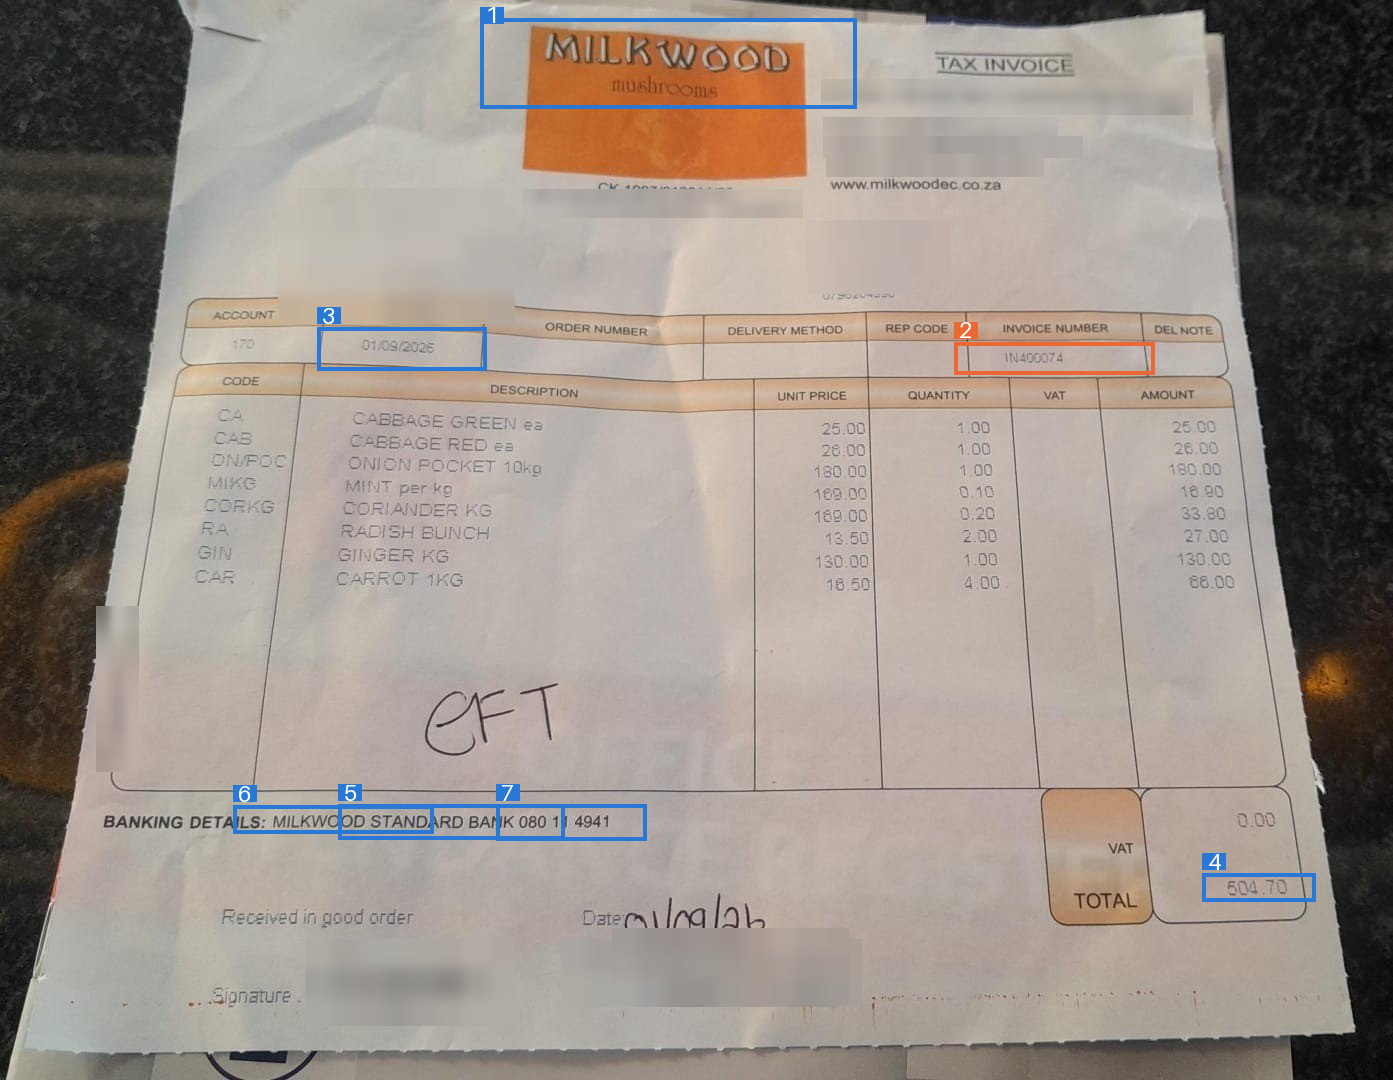

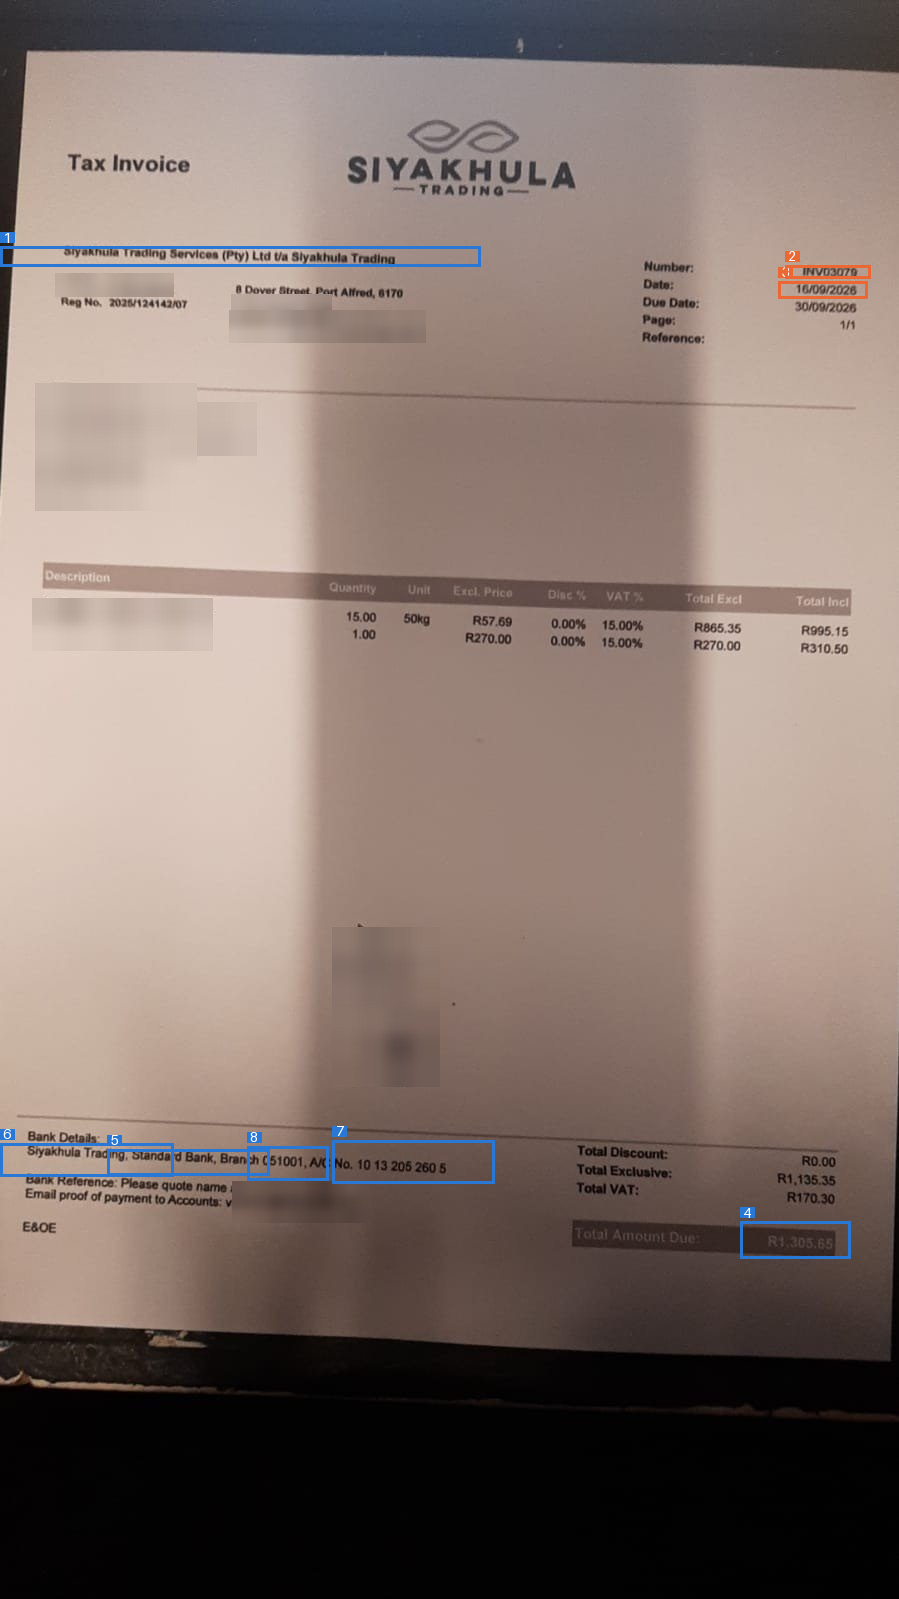

In [ ]:
BLUE, ORANGE = "#2a78d6", "#eb6834"


def annotate(photo: str, fields: dict) -> PILImage.Image:
    with PILImage.open(INPUTS / photo) as page:
        page = page.convert("RGB")
    draw = ImageDraw.Draw(page)
    font = ImageFont.load_default(size=max(14, page.width // 60))
    for field, r in fields.items():
        colour = ORANGE if r["review"] else BLUE
        b = r["box"]
        xy = (b["left"] * page.width, b["top"] * page.height,
              b["right"] * page.width, b["bottom"] * page.height)
        draw.rectangle(xy, outline=colour, width=max(3, page.width // 300))
        label = f" {KEY[field]} "  # a small badge keeps fields on one printed line legible
        tx, ty = xy[0], max(0, xy[1] - font.size - 4)
        draw.rectangle(draw.textbbox((tx, ty), label, font=font), fill=colour)
        draw.text((tx, ty), label, fill="white", font=font)
    return page


for photo, fields in checked.items():
    display(annotate(photo, fields))